# От чего зависит средний чек в Пятерочке?
## Введение
Данный проект посвящен изучению зависимости среднего чека в одной из крупнейших российских сетей магазинов – Пятерочке.

Использован [датасет](https://dano.hse.ru/data2025#2) олимпиады по анализу данных, находящийся в открытом доступе.

В датасете представлена выгрузка информации о магазинах торговой сети Пятерочка за один календарный год. Данные собраны на уровне отдельных торговых точек и включают как операционные показатели (трафик, средний чек), так и внешние факторы окружения: инфраструктуру, плотность населения, соседние объекты и конкурентную среду. В целях защиты коммерческой тайны отдельные числовые поля были модифицированы. При этом сохранены относительные соотношения между значениями, чтобы данные оставались пригодными для анализа. На сайте олимпиады представлено более подробное [описание датасета](https://dano.hse.ru/mirror/pubs/share/1102761036.pdf).

## А что мы будем изучать?

Если кратко – зависимость среднего чека (в рублях, конечно) на разных уровнях от различных факторов, данные о которых есть в датасете. По отдельности данные магазинов за месяц, за год, по каждому региону и по каждому населенному пункту

## Предварительная обработка данных

После вывода всех использованных библиотек была произведена обработка первичного датасета. На каждом этапе очищены мешающие анализу выбросы и произведена "генерализация" магазинов до нужного масштаба. Более подробно шаги описаны далее:

In [29]:
import matplotlib.pyplot as plt #Использованные библиотеки
import numpy as np
import pandas as pd
import cartopy
import cartopy.crs as crs
import cartopy.feature as cfeature
import geopandas as gpd

In [30]:
df_old = pd.read_excel("data\Х5.xlsx") # Считываем исходный датасет

In [31]:
df_old # Выводим датафрейм для удобства

,new_id,Месяц,Трафик,Средний чек,"Дата открытия, категориальный","Торговая площадь, категориальный",Населенный пункт,Регион,Численность населения,Количество домохозяйств,"Трафик пеший, в час","Трафик авто, в час","Маркетплейсы, доставки, постаматы (100 м)",Медицинские уч. и аптеки (300 м),Школы (300 м),Остановки (300 м),Продуктовые магазины (500 м),Пятерочки (500 м)
0,0,10,59662,823.060390,Средний по возрасту,Средний,Кавказская ст-ца,Краснодарский край,10177,608,76.900,200.333333,0,6,0,0,2,0
1,0,5,56674,859.361975,Средний по возрасту,Средний,Кавказская ст-ца,Краснодарский край,10177,608,76.900,200.333333,0,6,0,0,2,0
2,0,1,51488,763.937766,Средний по возрасту,Средний,Кавказская ст-ца,Краснодарский край,10177,608,76.900,200.333333,0,6,0,0,2,0
3,0,6,56693,836.362309,Средний по возрасту,Средний,Кавказская ст-ца,Краснодарский край,10177,608,76.900,200.333333,0,6,0,0,2,0
4,0,7,58128,845.257709,Средний по возрасту,Средний,Кавказская ст-ца,Краснодарский край,10177,608,76.900,200.333333,0,6,0,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256718,21742,10,51676,1167.101083,Новый,Средний,Октябрьский рп,Волгоградская обл,6071,262,125.375,243.333333,1,1,0,0,1,0
256719,21742,11,51516,1252.914118,Новый,Средний,Октябрьский рп,Волгоградская обл,6071,262,125.375,243.333333,1,1,0,0,1,0
256720,21742,9,49593,1130.823998,Новый,Средний,Октябрьский рп,Волгоградская обл,6071,262,125.375,243.333333,1,1,0,0,1,0
256721,21742,12,52115,1461.929305,Новый,Средний,Октябрьский рп,Волгоградская обл,6071,262,125.375,243.333333,1,1,0,0,1,0


Данные для каждого магазина представлены за месяц. Нужно найти среднее за год по каждому магазину.
Запишем это в таблицу Х5_mean.xlsx и датафрейм df

In [32]:
mean_columns = ["Трафик", "Средний чек"] # Столбцы, для которых нужно найти среднее, остальные одинаковые для каждого месяца

other_columns = []

for column in df_old.columns:
    if column not in (["new_id", "Месяц"] and mean_columns): # Записываем все остальные столбцы,
        other_columns.append(column) #кроме ID (будет одно на весь файл для каждого магазина) и месяца (значения не будет, т.к. берем среднее)

agg_dict = {} # Создаeм словарь с операциями для столбцов

for column in mean_columns: # Для столбцов, в которых нужно посчитать среднее, добавляем их
    agg_dict[column] = "mean"

for column in other_columns: # Для остальных параметров -- первый (они одинаковые для каждого месяца)
    agg_dict[column] = "first"

df = df_old.groupby("new_id", as_index=False).agg(agg_dict) # Группируем данные по ID магазина

df = df.drop(columns=["Месяц"], errors="ignore") # Удаляем столбец "Месяц"

#df.to_excel("data\Х5_mean.xlsx", index=False)

In [33]:
df # Выводим датафрейм для удобства

,Трафик,Средний чек,new_id,"Дата открытия, категориальный","Торговая площадь, категориальный",Населенный пункт,Регион,Численность населения,Количество домохозяйств,"Трафик пеший, в час","Трафик авто, в час","Маркетплейсы, доставки, постаматы (100 м)",Медицинские уч. и аптеки (300 м),Школы (300 м),Остановки (300 м),Продуктовые магазины (500 м),Пятерочки (500 м)
0,56270.916667,836.085288,0,Средний по возрасту,Средний,Кавказская ст-ца,Краснодарский край,10177,608,76.900000,200.333333,0,6,0,0,2,0
1,71995.916667,663.014014,1,Средний по возрасту,Средний,Екатеринбург г,Свердловская обл,1544376,4152,166.142857,208.789474,1,2,2,3,6,1
2,63466.583333,1087.083774,2,Средний по возрасту,Маленький,Дубна г,Московская обл,74183,2278,74.437500,138.272727,10,0,1,1,0,0
3,69567.500000,1622.269179,3,Средний по возрасту,Большой,Подольск г,Московская обл,314934,3664,121.692308,432.050000,3,6,0,3,4,0
4,65873.750000,1126.653308,4,Средний по возрасту,Средний,Москва г,Москва г,12506468,6194,145.105263,307.437500,3,5,0,11,7,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21738,51445.200000,952.845026,21738,Новый,Средний,Некрасовский рп,Московская обл,11574,1424,49.166667,33.142857,2,0,0,4,3,0
21739,34161.000000,643.981817,21739,Новый,Средний,Безенчук пгт,Самарская обл,20516,915,88.625000,172.750000,0,0,0,0,3,2
21740,40194.666667,500.076936,21740,Новый,Маленький,Боковская ст-ца,Ростовская обл,4765,541,107.800000,97.000000,0,2,0,0,4,2
21741,44980.666667,834.202167,21741,Новый,Большой,Преображенская ст-ца,Волгоградская обл,4889,275,137.166667,223.333333,0,1,0,0,2,1


Объединим df по региону в файл Х5_settelment и датафрейм df_settelment (так как в датасете есть несколько магазинов в населенном пункте) по тому же принципу, что и df

In [34]:
agg_dict = {}
first_columns = ["Населенный пункт", "Регион", "Численность населения", "Количество домохозяйств"]

agg_dict["Средний чек"] = "mean" 
for column in first_columns:
    agg_dict[column] = "first"

df_settelment = df.groupby("Населенный пункт", as_index=False).agg(agg_dict) # Группируем данные по названию населенного пункта

# Очистим таблицу от некорректных населенных пунктов с нулевыми значениями
# Также есть населенные пункты, в которых некорректная численность населения: она продублировалась с крупными городами.
# Чтобы это исправить, отсортируем населенные пункты, чтобы города (содержат в названии " г") стояли в таблице первее
df_settelment = df_settelment[df_settelment["Численность населения"] != 0] 
df_settelment = df_settelment.sort_values(by="Населенный пункт", key=lambda x: x.str.contains(" г", na=False), ascending=False)

# Удалим остальные строчки
df_settelment = df_settelment.drop_duplicates(subset=["Численность населения"], keep='first')

#df_settelment.to_excel("data\Х5_settelment.xlsx", index=False)

In [35]:
df_settelment # Выводим датафрейм для удобства

,Средний чек,Населенный пункт,Регион,Численность населения,Количество домохозяйств
2232,1173.680200,Оленегорск г,Мурманская обл,21438,4225
1792,755.612913,Мантурово г,Костромская обл,13043,2249
3020,1034.948473,Сычевка г,Смоленская обл,7544,753
1785,715.639998,Мамадыш г,Татарстан Респ,15726,811
1787,868.018405,Мамоново г,Калининградская обл,7953,1337
...,...,...,...,...,...
1472,948.086846,Красносельск п,Ульяновская обл,773,275
1474,1212.983820,Красносельское с,Краснодарский край,4734,272
1478,734.633519,Красноусольский с,Башкортостан Респ,11241,556
1480,699.901992,Краснохолмский с,Башкортостан Респ,7767,776


Теперь объединим df по региону в файл Х5_region и датафрейм df_region (так как в датасете есть несколько магазинов в населенном пункте и некоторое количество населенных пунктов в регионе)

Пятерочки есть не в каждом регионе, поэтому их получилось 72

In [36]:
mean_columns = [
    "Трафик", "Средний чек", 
    "Трафик пеший, в час", "Трафик авто, в час"
] # Столбцы, для которых нужно найти среднее

agg_dict = {} # Создаём словарь с операциями для столбцов

agg_dict["Регион"] = "first"
for column in mean_columns: # Для посчитанных средних параметров добавляем их
    agg_dict[column] = "mean"

df_region = df.groupby("Регион", as_index=False).agg(agg_dict) # Группируем данные по названию региона

#df_region.to_excel("data\Х5_region.xlsx", index=False)

In [37]:
df_region

,Регион,Трафик,Средний чек,"Трафик пеший, в час","Трафик авто, в час"
0,Адыгея Респ,54622.983719,800.754242,101.245163,248.752822
1,Алтай Респ,52756.322917,1011.610008,224.392795,337.525663
2,Алтайский край,50957.904960,798.353839,207.738510,215.199142
3,Архангельская обл,53949.268363,856.449984,117.292657,116.198782
4,Астраханская обл,54425.565039,797.452095,126.817444,218.240924
...,...,...,...,...,...
67,Ханты-Мансийский Автономный округ - Югра АО,56427.414403,1043.499662,105.247801,113.138762
68,Челябинская обл,57118.149875,824.593321,120.594393,147.562403
69,Чувашская Республика - Чувашия,58999.048398,801.851286,128.595182,177.028644
70,Ямало-Ненецкий АО,62187.556306,1418.591540,252.055850,232.606930


## Предварительный анализ

Посмотрим на средний чек в цифрах и на графике-боксплоте. Средний чек, посчитанный для каждого магазина на каждый месяц, составил 966.3 рубля, максимальное же значение более чем в четыре раза больше. Для дальнейшего анализа выбросы в значениях среднего чека убраны не были для сохранения полноты картины

In [38]:
df_old['Средний чек'].describe()

count    256723.000000
mean        966.307537
std         323.686240
min           0.000000
25%         739.827669
50%         901.419357
75%        1126.586033
max        3911.501606
Name: Средний чек, dtype: float64

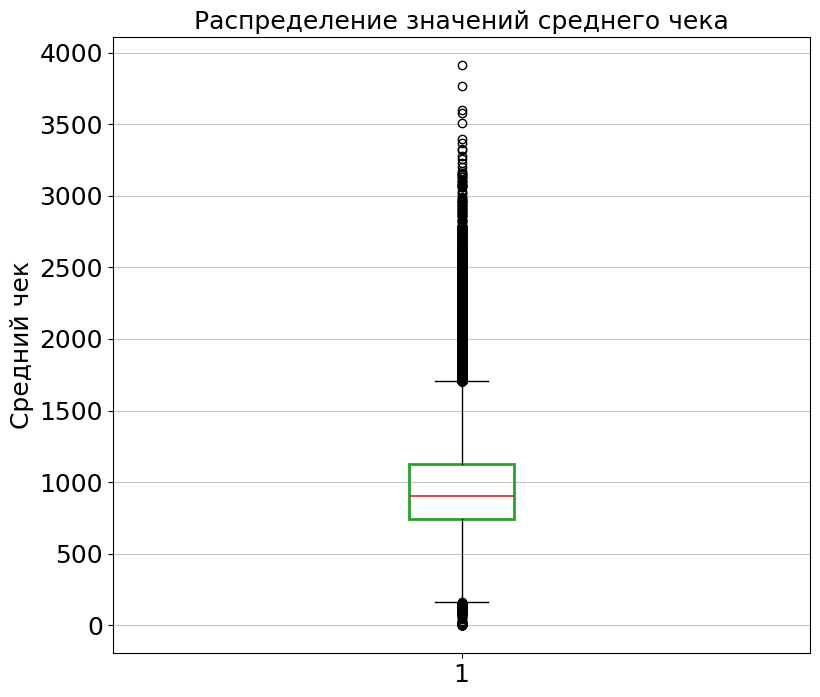

In [39]:
plt.figure(figsize=(9,8))

plt.boxplot(df_old['Средний чек'], patch_artist=True, # Построение и настройка визуализации боксплота
                boxprops=dict(facecolor='none', color='C2', linewidth=2),
                medianprops=dict(color='C3', linewidth=1.2))

plt.ylabel("Средний чек", fontsize=18) # Настройки осей, названия графика
plt.title("Распределение значений среднего чека", fontsize=18)
plt.gca().tick_params(labelsize=18)

plt.grid(axis='y', alpha=0.7)
plt.show()

## Зависимость среднего чека от месяца в году

Построим график зависимости среднего чека в Пятерочке от месяца в году в виде столбчатой диаграммы. На протяжении года средний чек колеблется, немного возрастая к лету, но самое значительное увеличение наблюдается в декабре, и связанно с празднованием Нового года. Интересно, что минимальный средний чек наблюдается в январе (что можно связать с сокращением денег после новогодних праздников) и в сентябре (что можно связать с вынужденным сокращением расходов после лета и, например, сбора детей в школу)

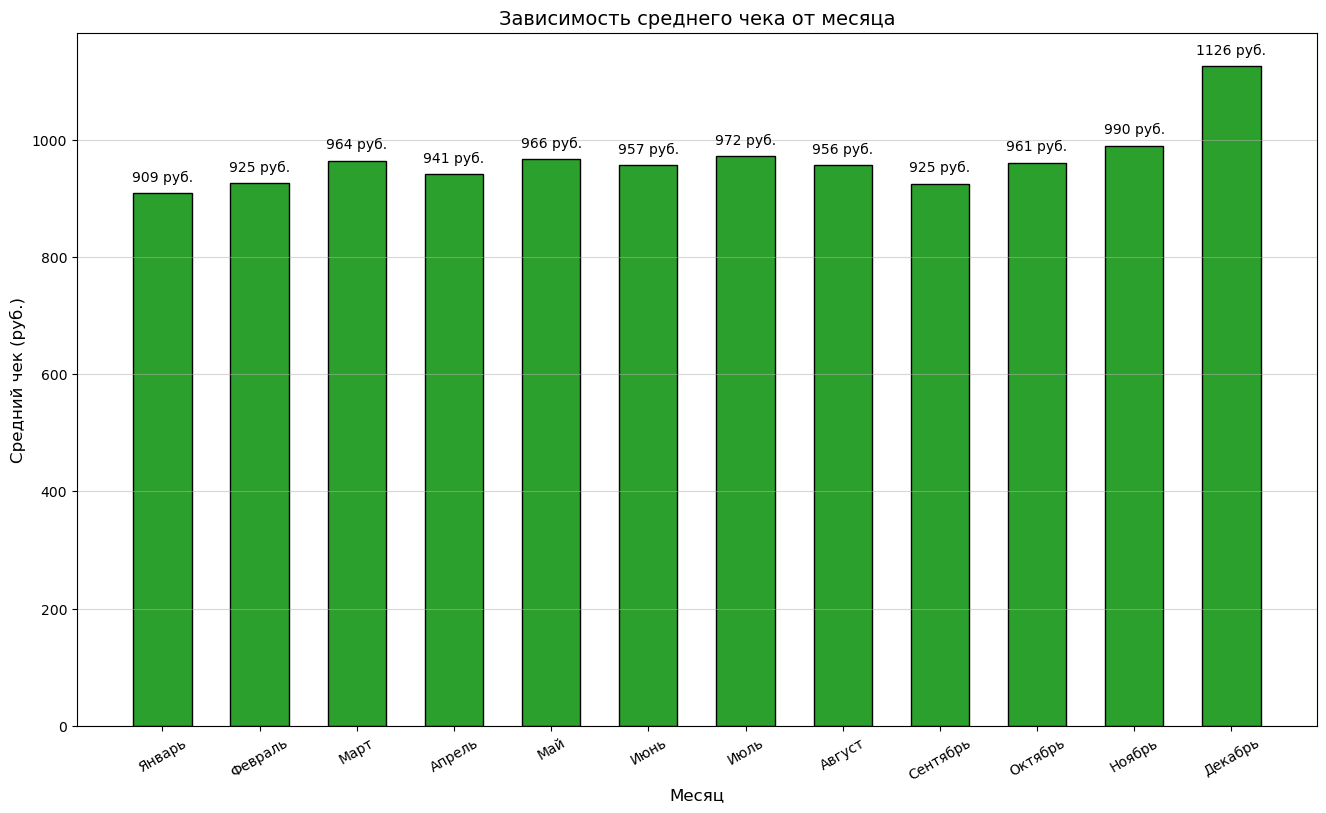

In [40]:
monthly_check = df_old.groupby('Месяц')['Средний чек'].mean().reset_index() # Группируем исходные данные по месяцам и находим средний чек среди всех магазинов

# Словарь для замены номеров месяцев на их названия
months_ru = {
    1: 'Январь', 2: 'Февраль', 3: 'Март', 4: 'Апрель', 
    5: 'Май', 6: 'Июнь', 7: 'Июль', 8: 'Август', 
    9: 'Сентябрь', 10: 'Октябрь', 11: 'Ноябрь', 12: 'Декабрь'
}

monthly_check['Название месяца'] = monthly_check['Месяц'].map(months_ru) # Применяем названия месяцев для оси X

plt.figure(figsize=(16, 9))

bars = plt.bar(monthly_check['Название месяца'], monthly_check['Средний чек'], # Строим столбчатую диаграмму
               color='C2', edgecolor='black', width=0.6)

# Добавляем точные значения среднего чека над каждым столбцом
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 15, f'{round(yval)} руб.', 
             ha='center', va='bottom', fontsize=10)

plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Средний чек (руб.)', fontsize=12)
plt.title('Зависимость среднего чека от месяца', fontsize=14)
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.5)

#plt.savefig('figures/average_check_from_month.png', dpi=300)
#plt.savefig('figures/average_check_from_month.eps')

plt.show()

## Зависимость среднего чека от трафика

Построим график зависимости среднего чека в Пятерочке от трафика в виде диаграммы рассеяния. Облако точек вытянуто вдоль линии тренда, а коээфициент линейной корреляции Пирсона составляет 0.66, что свидетельствует о заметной связи, причем довольно близкой к сильной.

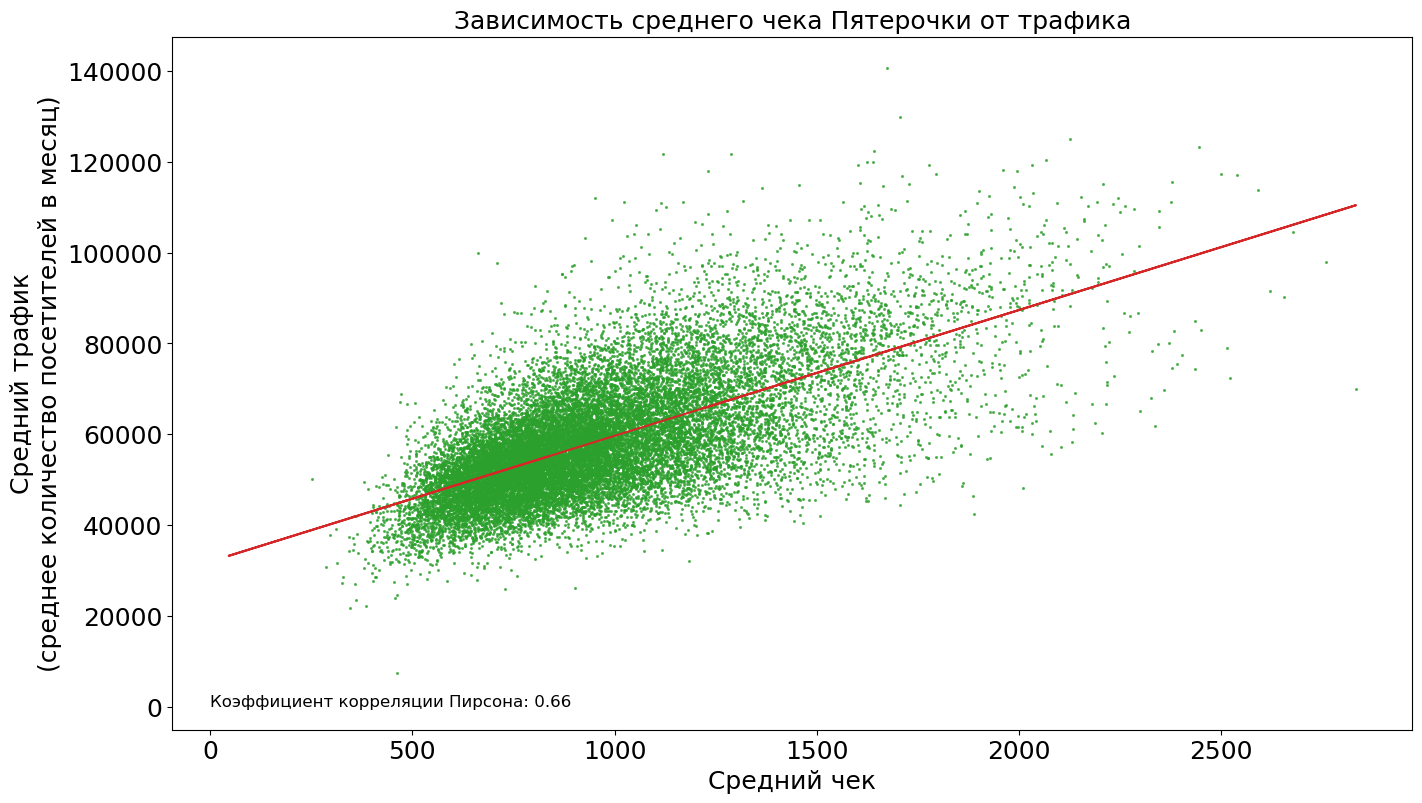

In [41]:
# Визуализируем зависимость среднего чека Пятерочки от трафика
plt.figure(figsize=(16,9))

z = np.polyfit(df['Средний чек'], df['Трафик'], deg=1) # Cчитаем коэффициенты линейной регрессии
p = np.poly1d(z)

plt.scatter(df['Средний чек'], df['Трафик'], color='C2', s=1.5, alpha=0.7) # Визуализируем сам график

plt.plot(df['Средний чек'], p(df['Средний чек']), color='C3') # Визуализируем линейную регрессию
corr = df['Средний чек'].corr(df['Трафик'])

plt.text(
    0, 0,
    f'Коэффициент корреляции Пирсона: {np.round(corr, 2)}',
    fontsize=12,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none') # Выводим коэффициент корреляции Пирсона
)
plt.xlabel("Средний чек", fontsize=18) # Настройки осей, названия графика
plt.ylabel("Средний трафик\n(среднее количество посетителей в месяц)", fontsize=18)
plt.title("Зависимость среднего чека Пятерочки от трафика", fontsize=18)
plt.gca().tick_params(labelsize=18)

#plt.savefig('figures/average_check_from_traffic.png', dpi=300)
#plt.savefig('figures/average_check_from_traffic.eps')

plt.show()

## Зависимость среднего чека от пешего и автомобильного трафика

Поделим трафик на пеший и автомобильный. Что-то изменится?

Картина довольно сильно поменялась: корреляция низкая, и, вероятно это связано с масштабом параметра: трафик в час зависит от времени суток, и в совокупности со средним чеком не показывает зависимость по часам (таких данных по среднему чеку нет в датасете)

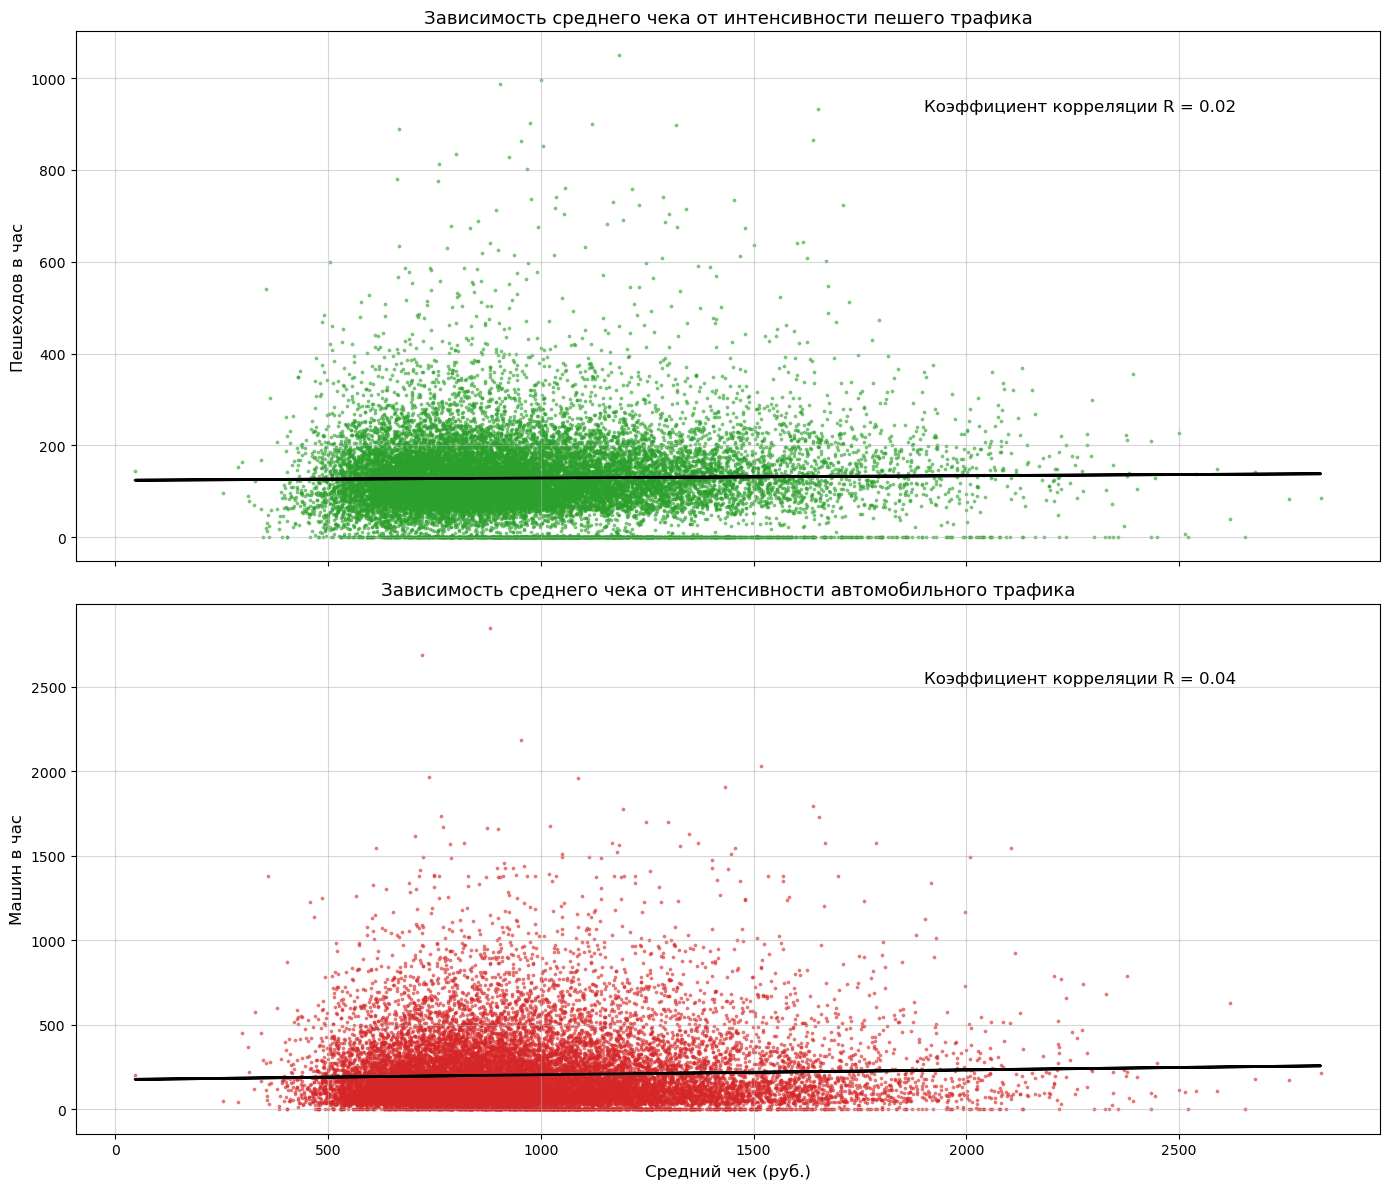

In [42]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12), sharex=True)

# 1. ГРАФИК ПЕШЕГО ТРАФИКА

axes[0].scatter(df['Средний чек'], df['Трафик пеший, в час'], color='C2', s=3, alpha=0.5) # Отображаем точки и линию тренда

z_walk = np.polyfit(df['Средний чек'], df['Трафик пеший, в час'], deg=1)
p_walk = np.poly1d(z_walk)
axes[0].plot(df['Средний чек'], p_walk(df['Средний чек']), color='black', linewidth=2)

corr_walk = df['Средний чек'].corr(df['Трафик пеший, в час']) # Расчёт корреляции

axes[0].text(0.65, 0.85, f'Коэффициент корреляции R = {np.round(corr_walk, 2)}', # Текстовое обозначение на графике
            color='black', fontsize=12, transform=axes[0].transAxes)

axes[0].set_ylabel('Пешеходов в час', fontsize=12)
axes[0].set_title('Зависимость среднего чека от интенсивности пешего трафика', fontsize=13)
axes[0].grid(True, alpha=0.5)

# 2. ГРАФИК АВТОМОБИЛЬНОГО ТРАФИКА

axes[1].scatter(df['Средний чек'], df['Трафик авто, в час'], color='C3', s=3, alpha=0.5) # Отображаем точки и линию тренда

z_car = np.polyfit(df['Средний чек'], df['Трафик авто, в час'], deg=1)
p_car = np.poly1d(z_car)
axes[1].plot(df['Средний чек'], p_car(df['Средний чек']), color='black', linewidth=2)

corr_car = df['Средний чек'].corr(df['Трафик авто, в час']) # Расчёт корреляции

axes[1].text(0.65, 0.85, f'Коэффициент корреляции R = {np.round(corr_car, 2)}', # Текстовое обозначение на графике
            color='black', fontsize=12, transform=axes[1].transAxes)

axes[1].set_xlabel('Средний чек (руб.)', fontsize=12)
axes[1].set_ylabel('Машин в час', fontsize=12)
axes[1].set_title('Зависимость среднего чека от интенсивности автомобильного трафика', fontsize=13)
axes[1].grid(True, alpha=0.5)

#plt.savefig('figures/average_check_from_traffic_auto_and_ped.png', dpi=300)
#plt.savefig('figures/average_check_from_traffic_auto_and_ped.eps')

plt.tight_layout()
plt.show()

## Зависимость среднего чека от новизмы магазина и торговой площади

Построим график распредления среднего чека в зависимости от новизмы магазина и торговой площади в виде боксплота.

Для новизны магазина существуют три категории: новый, средний по возрасту и открытый давно. В давно открытых магазинах чек оказался на 200-300 руб больше, чем в средних по возрасту и новых. Интересно то, что максимальные значения чека почти одинаковые для трех категорий, но для новых и средних магазинов они получили статус выбросов. Минимальные значения в открытых давно магазинах оказываются выше, чем в более новых. Это распредление объясняется тем, что магазин уже хорошо "вписался" в окружающую среду, и люди привыкли в него ходить, считают проверенным.

Для площади магазина существуют три категории: маленький, средний, большой и очень большой. С увеличением площади увеличивается и средний чек, причем как минимальные и максимальные значения (за исключением одного выброса в средней категории площади), так и разброс 50% всех наблюдений. Маленькие по площади магазины, как правило, располагаются в спальных районах, и туда люди заходят за повседневными небольшими по стоимости покупками. В большие же магазины люди часто ездят, специально планируя масштабные покупки.

In [43]:
# Изучим уникальные категории в данных для фильтрации
print("Категории новизны:", df['Дата открытия, категориальный'].unique())
print("Категории площади:", df['Торговая площадь, категориальный'].unique())

Категории новизны: ['Средний по возрасту' 'Новый' 'Открыт давно']
Категории площади: ['Средний' 'Маленький' 'Большой' 'Очень большой']


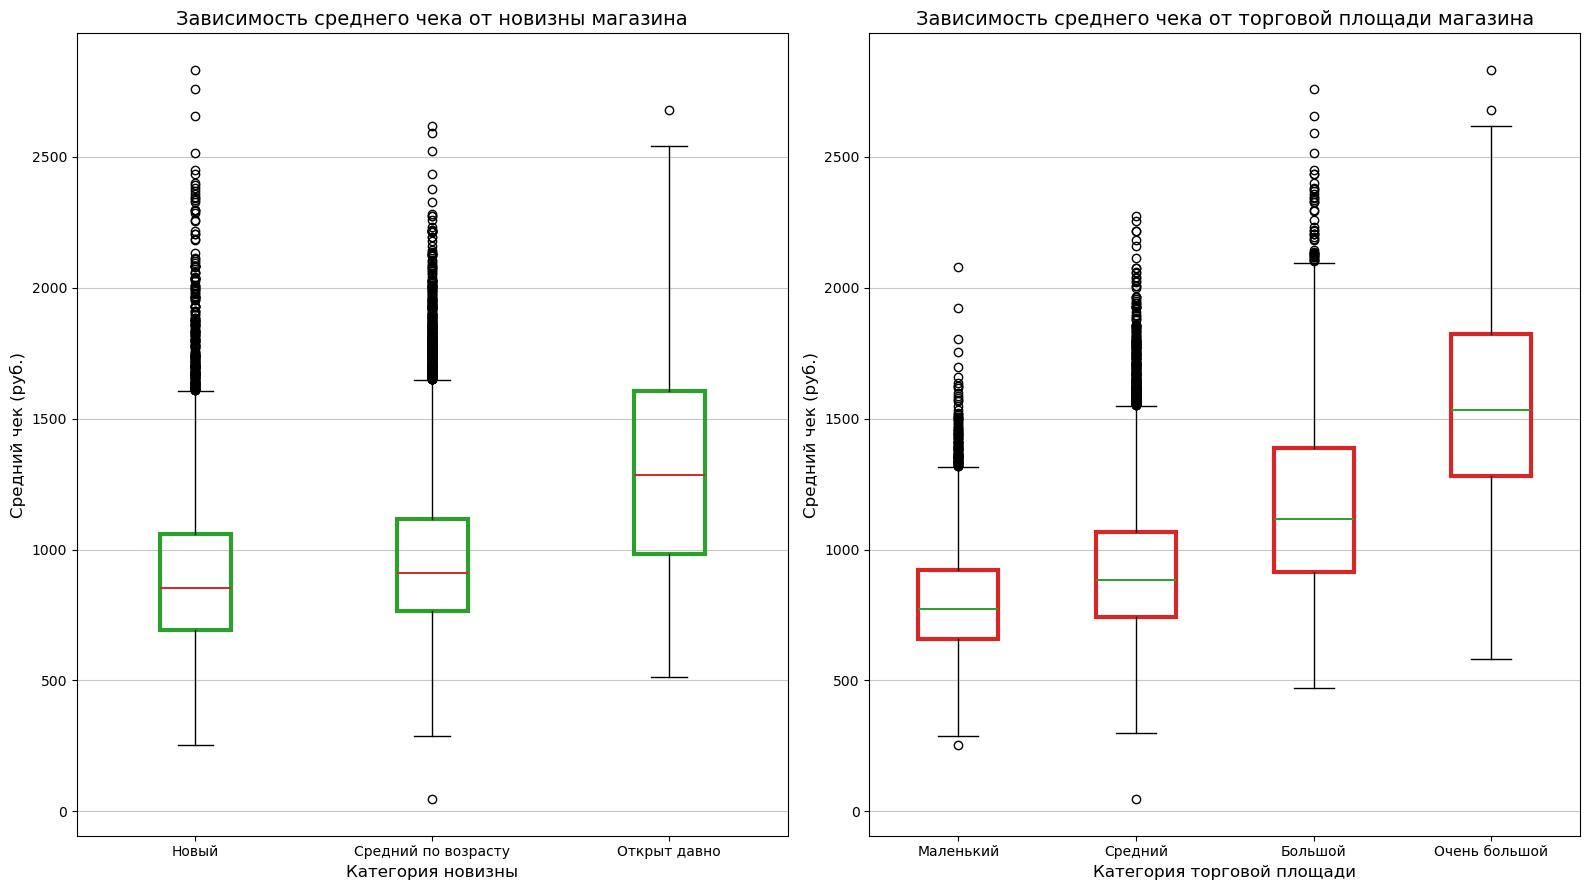

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# 1. ЗАВИСИМОСТЬ СРЕДНЕГО ЧЕКА ОТ НОВИЗНЫ МАГАЗИНА

categories_age = ['Новый', 'Средний по возрасту', 'Открыт давно'] # Задаём порядок категорий новизны (от новых к старым)

data_by_age = [] # Создаём список датафреймов через маски для каждой категории новизны
for category in categories_age:
    mask = df['Дата открытия, категориальный'] == category
    data_by_age.append(df[mask]['Средний чек'])
    
axes[0].boxplot(data_by_age, tick_labels=categories_age, patch_artist=True, # Строим Boxplot для новизны магазинов
                boxprops=dict(facecolor='none', color='C2', linewidth=3),
                medianprops=dict(color='C3', linewidth=1.4))

axes[0].set_title('Зависимость среднего чека от новизны магазина', fontsize=14)
axes[0].set_xlabel('Категория новизны', fontsize=12)
axes[0].set_ylabel('Средний чек (руб.)', fontsize=12)
axes[0].grid(axis='y', alpha=0.7)

# 2. ЗАВИСИМОСТЬ СРЕДНЕГО ЧЕКА ОТ ТОРГОВОЙ ПЛОЩАДИ

categories_area = ['Маленький', 'Средний', 'Большой', 'Очень большой'] # Задаём порядок категорий площади (от меньшего к большему)

data_by_area = [] # Создаём список датафреймов через маски для каждой категории торговой площади
for category in categories_area:
    mask = df['Торговая площадь, категориальный'] == category
    data_by_area.append(df[mask]['Средний чек'])

axes[1].boxplot(data_by_area, tick_labels=categories_area, patch_artist=True, # Строим Boxplot для торговой площади магазинов
                boxprops=dict(facecolor='none', color='C3', linewidth=3),
                medianprops=dict(color='C2', linewidth=1.4))

axes[1].set_title('Зависимость среднего чека от торговой площади магазина', fontsize=14)
axes[1].set_xlabel('Категория торговой площади', fontsize=12)
axes[1].set_ylabel('Средний чек (руб.)', fontsize=12)
axes[1].grid(axis='y', alpha=0.7)

plt.tight_layout()

#plt.savefig('figures/average_check_categorical_analysis_boxplot.png', dpi=300)
#plt.savefig('figures/average_check_categorical_analysis_boxplot.eps')

plt.show()

## Альтернативный способ отображения

Есть альтернативный способ отображения: так называемая скрипичная диаграмма. Нам показалось интересным поработать с ней тоже, но для анализа этих данных violin plot оказался менее подходящим и удобным способом отображения. Интересно, что большее количество средних чеков концентрируюется в значениях под медианой.

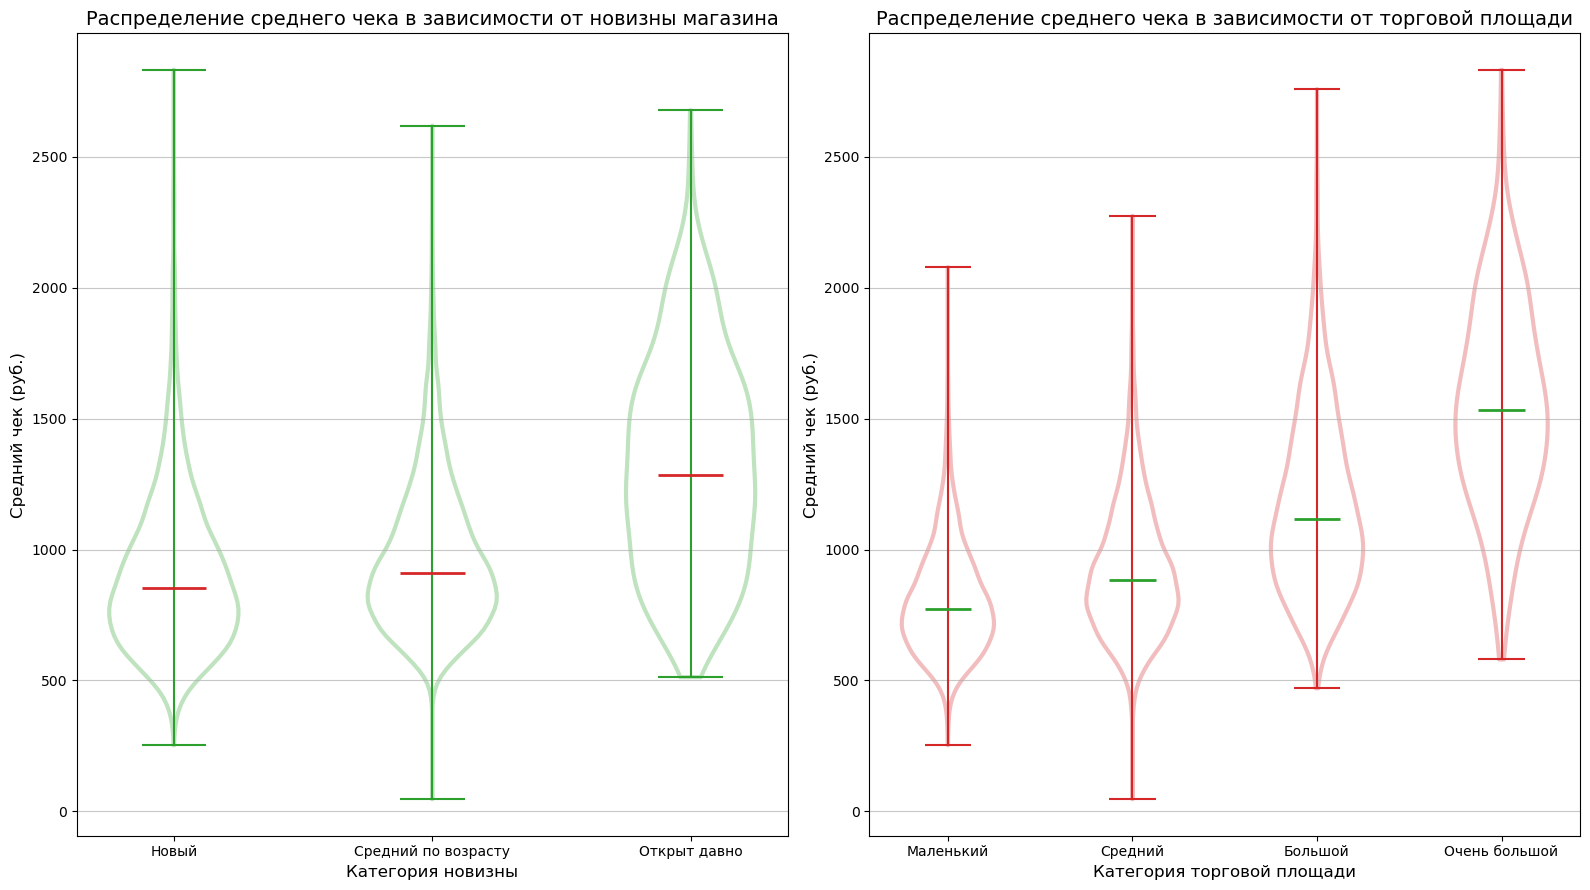

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# 1. ЗАВИСИМОСТЬ СРЕДНЕГО ЧЕКА ОТ НОВИЗНЫ МАГАЗИНА

categories_age = ['Новый', 'Средний по возрасту', 'Открыт давно']

data_by_age = []
for category in categories_age:
    mask = df['Дата открытия, категориальный'] == category
    data_by_age.append(df[mask]['Средний чек'].values)

vplot1 = axes[0].violinplot(data_by_age, showmedians=True, showextrema=True) # Строим Violin Plot для новизны магазинов

# Кастомизация внешнего вида
for body in vplot1['bodies']:
    body.set_facecolor('none')      
    body.set_edgecolor('C2')    
    body.set_linewidth(3)           

# Настройка цветов линий медианы и экстремумов
vplot1['cmedians'].set_colors('C3')
vplot1['cmedians'].set_linewidth(2)
vplot1['cmins'].set_colors('C2')
vplot1['cmaxes'].set_colors('C2')
vplot1['cbars'].set_colors('C2')

axes[0].set_xticks(range(1, len(categories_age) + 1))
axes[0].set_xticklabels(categories_age)
axes[0].set_title('Распределение среднего чека в зависимости от новизны магазина', fontsize=14)
axes[0].set_xlabel('Категория новизны', fontsize=12)
axes[0].set_ylabel('Средний чек (руб.)', fontsize=12)
axes[0].grid(axis='y', alpha=0.7)

# 2. ЗАВИСИМОСТЬ СРЕДНЕГО ЧЕКА ОТ ТОРГОВОЙ ПЛОЩАДИ

categories_area = ['Маленький', 'Средний', 'Большой', 'Очень большой']

data_by_area = []
for category in categories_area:
    mask = df['Торговая площадь, категориальный'] == category
    data_by_area.append(df[mask]['Средний чек'].values)

vplot2 = axes[1].violinplot(data_by_area, showmedians=True, showextrema=True) # Строим Violin Plot для торговой площади магазинов

# Кастомизация внешнего вида
for body in vplot2['bodies']:
    body.set_facecolor('none')      
    body.set_edgecolor('C3')   
    body.set_linewidth(3)         

# Настройка цветов линий медианы и экстремумов
vplot2['cmedians'].set_colors('C2')
vplot2['cmedians'].set_linewidth(2)
vplot2['cmins'].set_colors('C3')
vplot2['cmaxes'].set_colors('C3')
vplot2['cbars'].set_colors('C3')

axes[1].set_xticks(range(1, len(categories_area) + 1))
axes[1].set_xticklabels(categories_area)
axes[1].set_title('Распределение среднего чека в зависимости от торговой площади', fontsize=14)
axes[1].set_xlabel('Категория торговой площади', fontsize=12)
axes[1].set_ylabel('Средний чек (руб.)', fontsize=12)
axes[1].grid(axis='y', alpha=0.7)

#plt.savefig('figures/average_check_categorical_analysis_violin_plot.png', dpi=300)
#plt.savefig('figures/average_check_categorical_analysis_violin_plot.eps')

plt.tight_layout()
plt.show()

## Зависимость среднего чека от внешних факторов

Визуализируем зависимость среднего чека в Пятерочке от внешних факторов с помощью шести диаграмм рассеяния.

Количество маркетплейсов, доставок, постаматов в радиусе 100 м повышает средний чек, но скорее связано с оживленностью и проходимостью места. Количество медицинских учреждений, аптек и школ на средний чек совсем не влияет: социальные категории, которые часто бывают в данных местах, если и заходят в магазин, чаще берут что-то недорогое и в целом тратят мало денег. Количество остановок также слабо влияет на средний чек: люди, пользующиеся общественным транспортом, чаще купят продукты у дома, чтобы не нести сумки в полном автобусе.

Количество продуктовых магазинов поблизости (и Пятерочек в частности) даже снижает средний чек: люди могут заходить в разные магазины в разнеы дни, а также докупать что-то в другом месте, если забыли.

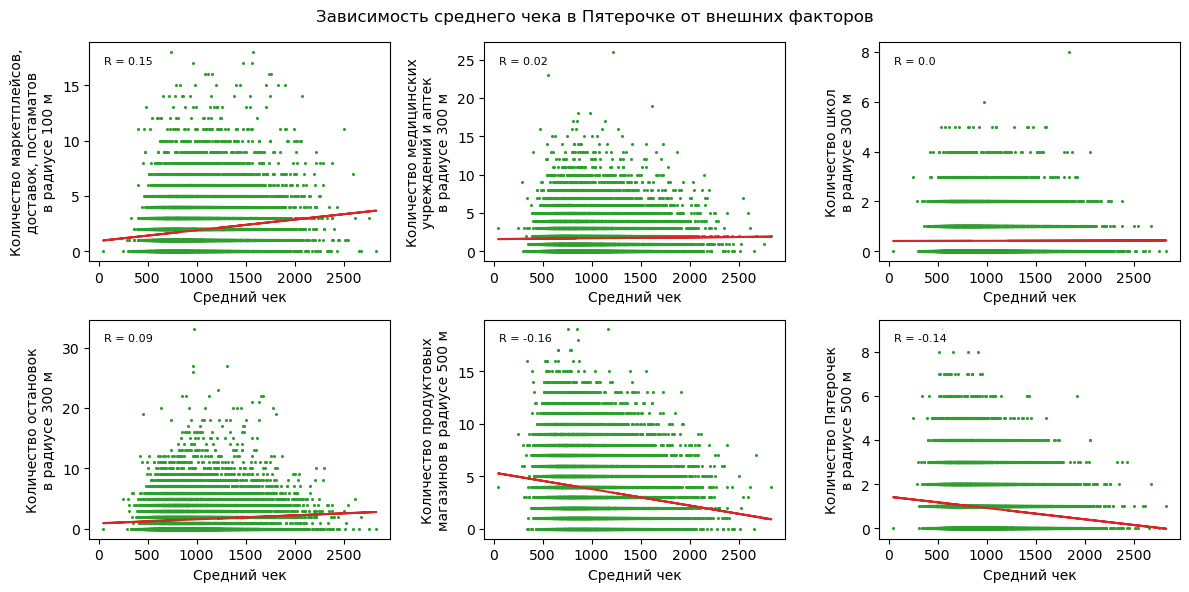

In [46]:
# Визуализируем зависимость среднего чека в Пятерочке от внешних факторов

fig, axes = plt.subplots(2, 3, figsize=(12, 6))

# Строим 6 графиков на одной фигуре, по оси x всегда средний чек (столбец с индексом 1 в таблице), по оси y -- столбцы с индексом от 11 до 16
# Также строим линейную регрессию
for i in range(2): 
    for j in range(3):
        ax = axes[i, j]
        ax.scatter(df.iloc[:, 1], df.iloc[:, i * 3 + j + 11], color='C2', s=1.5)
        z = np.polyfit(df.iloc[:, 1], df.iloc[:, i * 3 + j + 11], deg=1)
        p = np.poly1d(z)
        ax.plot(df.iloc[:, 1], p(df.iloc[:, 1]), color='C3')
        
fig.suptitle('Зависимость среднего чека в Пятерочке от внешних факторов', fontsize=12) # Оформляем оси, название и т.д.

for i in range(2):
    for j in range(3):
        axes[i, j].set_xlabel('Средний чек', fontsize=10)
        corr = df.iloc[:, 1].corr(df.iloc[:, i * 3 + j + 11])
        axes[i, j].text(
    0.05, 0.9,
    f'R = {np.round(corr, 2)}',
    transform=axes[i, j].transAxes,
    fontsize=8,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none') # Выводим коэффициент корреляции Пирсона
)
        
axes[0, 0].set_ylabel('Количество маркетплейсов,\nдоставок, постаматов\nв радиусе 100 м', fontsize=10)
 
axes[0, 1].set_ylabel('Количество медицинских\nучреждений и аптек\nв радиусе 300 м', fontsize=10)
 
axes[0, 2].set_ylabel('Количество школ\nв радиусе 300 м', fontsize=10)
 
axes[1, 0].set_ylabel('Количество остановок\nв радиусе 300 м', fontsize=10)

axes[1, 1].set_ylabel('Количество продуктовых\nмагазинов в радиусе 500 м', fontsize=10)

axes[1, 2].set_ylabel('Количество Пятерочек\nв радиусе 500 м', fontsize=10)

for i in range(2):
    for j in range(3):
        axes[i, j].tick_params(labelsize=10)

plt.tight_layout()

#plt.savefig('figures/average_check_from_external_factors.png', dpi=300)
#plt.savefig('figures/average_check_from_external_factors.eps')

plt.show()

## Зависимость среднего чека от численности населения

Построим график зависимости среднего чека в Пятерочке от численности населения, опять же, в виде диаграмм рассеяния. Воспользуемся делением согласно своду правил СП 42.13330.2016 «Градостроительство. Планировка и застройка городских и сельских поселений» (крупнейшие: свыше 1 млн человек, крупные: от 250 тыс. до 1 млн человек, большие: от 100 тыс. до 250 тыс. человек, средние: от 50 тыс. до 100 тыс. человек, малые: менее 50 тыс. человек). Для анализа применим это деление и для городских, и для сельских поселений.

В городах-миллионниках наблюдается сильная корреляция между средним чеком и численностью населения: чем больше население, тем больше средний чек, что связано с более высокими ценами в этих городах (в том числе из-за аренды площади магазина и прочих внешних факторов). В населенных пунктах с меньшим количеством населения связь наблюдается более слабая. Интересно, что в малых населенных пунктам сильнее всего прослеживается обратная зависимость: чем меньше численность населения, тем больше средний чек. Вероятно. там наблюдается картина, очень похожая на города-миллионники: высокие цены на продукты, но уже не из-за дороговизны аренды, а из-за сложностей логистики.

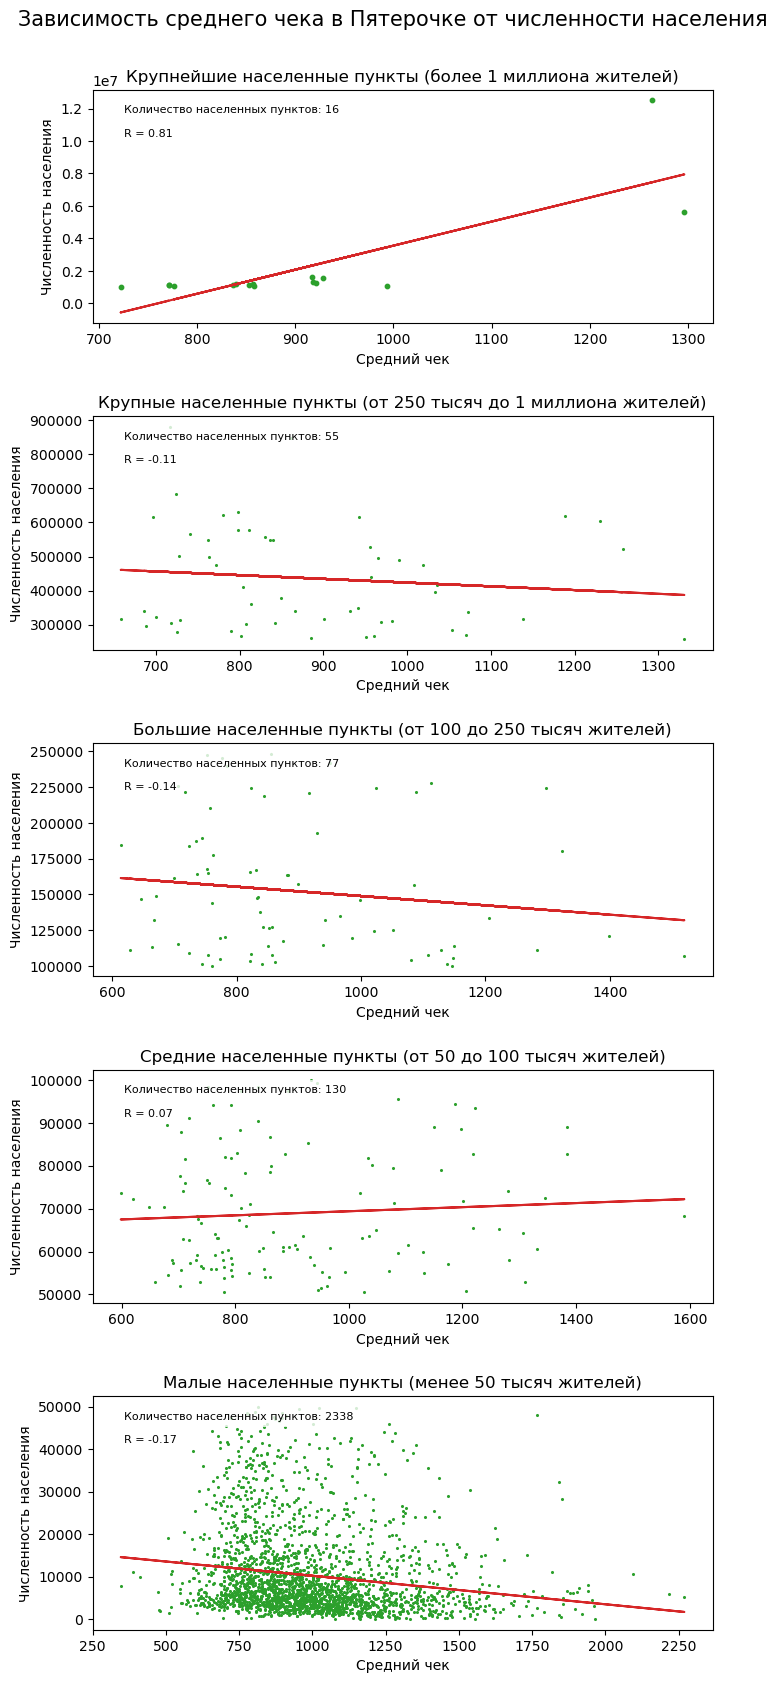

In [47]:
# Построим график зависимости среднего чека в Пятерочке от численности населения
fig, axes = plt.subplots(5, 1, figsize=(8, 20))

# Применяем маску в соответствии с российской типологией деления городов по численности населения
# Строим график, считаем коэф. лин. регрессии, корреляцию, выводим на график
for i in range(5):
    if i == 0:
        mask = df_settelment['Численность населения'] >= 1000000
    if i == 1:
        mask = (df_settelment['Численность населения'] < 1000000) & (df_settelment['Численность населения'] >= 250000)
    if i == 2:
        mask = (df_settelment['Численность населения'] < 250000) & (df_settelment['Численность населения'] >= 100000)
    if i == 3:
        mask = (df_settelment['Численность населения'] < 100000) & (df_settelment['Численность населения'] >= 50000)
    if i == 4:
        mask = df_settelment['Численность населения'] < 50000
    if i == 0:
        axes[0].scatter(df_settelment['Средний чек'][mask], df_settelment['Численность населения'][mask], color='C2', s=10)
    else:
        axes[i].scatter(df_settelment['Средний чек'][mask], df_settelment['Численность населения'][mask], color='C2', s=1.5)
    z = np.polyfit(df_settelment['Средний чек'][mask], df_settelment['Численность населения'][mask], deg=1)
    p = np.poly1d(z)
    axes[i].plot(df_settelment['Средний чек'][mask], p(df_settelment['Средний чек'][mask]), color='C3')
    axes[i].text(
    0.05, 0.9,
    f'Количество населенных пунктов: {mask.sum()}',
    transform=axes[i].transAxes,
    fontsize=8,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none') # Выводим количество точек (населенных пунктов) на графике
)
    corr = df_settelment['Средний чек'][mask].corr(df_settelment['Численность населения'][mask])
    axes[i].text(
    0.05, 0.8,
    f'R = {np.round(corr, 2)}',
    transform=axes[i].transAxes,
    fontsize=8,
    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none') # Выводим коэффициент корреляции Пирсона
)

# Оформляем оси, название и т.д.
fig.suptitle('Зависимость среднего чека в Пятерочке от численности населения', fontsize=15, y=0.92)

for i in range(5):
    axes[i].set_xlabel('Средний чек', fontsize=10)
for i in range(5):
    axes[i].set_ylabel('Численность населения', fontsize=10)

axes[0].set_title('Крупнейшие населенные пункты (более 1 миллиона жителей)', fontsize=12)

axes[1].set_title('Крупные населенные пункты (от 250 тысяч до 1 миллиона жителей)', fontsize=12)

axes[2].set_title('Большие населенные пункты (от 100 до 250 тысяч жителей)', fontsize=12)

axes[3].set_title('Средние населенные пункты (от 50 до 100 тысяч жителей)', fontsize=12)

axes[4].set_title('Малые населенные пункты (менее 50 тысяч жителей)', fontsize=12)

for i in range(5):
    axes[i].tick_params(labelsize=10)
fig.subplots_adjust(hspace=0.4)

#plt.savefig('figures/average_check_from_population.png', dpi=300, bbox_inches='tight')
#plt.savefig('figures/average_check_from_population.eps', bbox_inches='tight')

plt.show()

## Зависимость среднего чека от региона

Рассмотрим зависимость среднего чека от региона с помощью карты, которая была составлена с помощью библиотек cartopy и geopandas. Не во всех регионах России есть магазины Пятерочка, поэтому субъекты без данных окрашены серым цветом.

Повышение среднего чека в регионах коррелирует как с более высоким уровнем жизни и зарплатами, так и с удаленностью от европейской части России и сложностями с логистикой (по этой же причине не во всех субъектах представлена эта сеть магазинов). Ярко выделяется Ямало-Ненецкий автономный округ – в нем действуют сразу два вышеперечисленных фактора.

In [48]:
regions = gpd.read_file("data/russia_regions.geojson") # Считываем файл с границами

In [49]:
regions # Для удобства выводим датафрейм

,region,federal_district,population,geometry
0,Пензенская область,Приволжский,1246609,"MULTIPOLYGON (((42.08174 53.748, 42.08525 53.7..."
1,Саратовская область,Приволжский,2404944,"MULTIPOLYGON (((42.50367 51.66712, 42.50393 51..."
2,Республика Мордовия,Приволжский,771373,"MULTIPOLYGON (((42.16337 54.25811, 42.16397 54..."
3,Тамбовская область,Центральный,966250,"MULTIPOLYGON (((39.91569 52.70885, 39.92159 52..."
4,Рязанская область,Центральный,1088918,"MULTIPOLYGON (((38.66598 54.25671, 38.67116 54..."
...,...,...,...,...
80,Ивановская область,Центральный,914725,"MULTIPOLYGON (((39.37401 56.81999, 39.37724 56..."
81,Костромская область,Центральный,571900,"MULTIPOLYGON (((40.3901 57.39873, 40.39234 57...."
82,Республика Марий Эл,Приволжский,672321,"MULTIPOLYGON (((45.62374 56.51404, 45.6277 56...."
83,Магаданская область,Дальневосточный,134315,"MULTIPOLYGON (((159.32425 61.80881, 159.32588 ..."


In [50]:
df_region_corrected = pd.read_excel("data\Х5_region_corrected.xlsx")
# Файл со скорректированными названиями регионов, в исходном датасете -- сокращенные, как и в полученном от него df_region

In [51]:
df_region_corrected # Для удобства выводим датафрейм

,Регион,Трафик,Средний чек,"Трафик пеший, в час","Трафик авто, в час"
0,Республика Адыгея,54622.983719,800.754242,101.245163,248.752822
1,Республика Алтай,52756.322917,1011.610008,224.392795,337.525663
2,Алтайский край,50957.904960,798.353839,207.738510,215.199142
3,Архангельская область,53949.268363,856.449984,117.292657,116.198782
4,Астраханская область,54425.565039,797.452095,126.817444,218.240924
...,...,...,...,...,...
67,Ханты-Мансийский автономный округ — Югра,56427.414403,1043.499662,105.247801,113.138762
68,Челябинская область,57118.149875,824.593321,120.594393,147.562403
69,Чувашская Республика,58999.048398,801.851286,128.595182,177.028644
70,Ямало-Ненецкий автономный округ,62187.556306,1418.591540,252.055850,232.606930


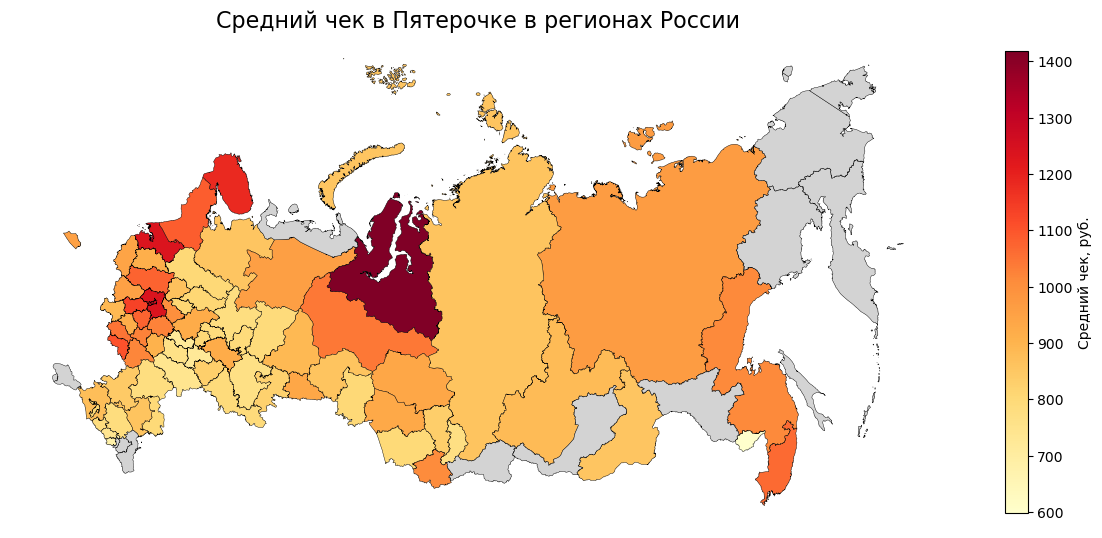

In [52]:
map_data_regions = regions.merge( # Объединяем границы с данными
    df_region_corrected[["Регион", "Средний чек"]],
    left_on="region",
    right_on="Регион",
    how="left"
)

map_data_regions = map_data_regions.to_crs("ESRI:102027") # Меняем проекцию, чтобы Чукотский полуостров был вместе с Россией :)
fig, ax = plt.subplots(figsize=(12, 8))

map_data_regions.plot( # Настраиваем отображение, регионы с "Нет данных" показываются серым
    column="Средний чек",
    cmap="YlOrRd",
    edgecolor="black",
    linewidth=0.3,
    legend=True,
    missing_kwds={
        "color": "lightgrey",
        "edgecolor": "black",
        "label": "Нет данных"
    },
    legend_kwds={
        "label": "Средний чек, руб.",
        "shrink": 0.6
    },
    ax=ax
)

ax.set_title("Средний чек в Пятерочке в регионах России", fontsize=16)
ax.set_axis_off()
plt.tight_layout()

#plt.savefig("figures/average_check_regions_russia.png",dpi=300, bbox_inches="tight")
#plt.savefig("figures/average_check_regions_russia.eps", bbox_inches="tight")

plt.show()

## Результаты

В результате исследования датасета была обнаружена зависимость среднего чека в Пятерочке от месяца, новизмы магазина и площади, частично от внешних факторов (количества маркетплейсов, доставок и постаматов, продуктовых магазинов и магазинов Пятерочки поблизости), а также частично от численности населения. Также была составлена карта среднего чека в Пятерочке по регионам.

Далее возможная более точечная проработка и анализ отдельных факторов, в том числе с применением сторонних датасетов и усложенных инструментов, в том числе других бибилиотек, например, seaborn.

## Список авторов

**Енбаева Татьяна** (первичная обработка данных, создание таблиц и датафреймов, графики зависимости среднего чека от трафика, внешних факторов, численности населения и построение карты среднего чека в Пятерочке по регионам России) и **Тимофей Филиппов** (построение графиков зависимости среднего чека от месяца, по новизны магазина и площади, от автомобильного и пешего трафика), студенты группы БГЕО252



## Примечания

Для удобства работы необходимо загрузить дополнительные библиотеки geopandas и cartopy. Ниже представлен код для их установки через conda.

```conda install -c conda-forge geopandas cartopy```